In [ ]:

!pip install wbgapi openpyxl statsmodels scikit-learn mlxtend

In [ ]:
# 데이터 수집 및 분석에 필요한 라이브러리 불러오기

!apt-get install -y fonts-nanum
import matplotlib.font_manager as fm
fm._load_fontmanager(try_read_cache=False)

import wbgapi as wb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import MinMaxScaler
from scipy import stats

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 3 not upgraded.


In [ ]:
indicators = {
    'IT.NET.USER.ZS': 'internet_penetration',   # 인터넷 보급률
    'NY.GDP.PCAP.CD': 'GDP_per_capita',          # 1인당 GDP
    'SE.ADT.LITR.ZS': 'literacy_rate',           # 교육수준
    'SP.URB.TOTL.IN.ZS': 'urbanization',         # 도시화율
    'IT.CEL.SETS.P2': 'mobile_subscriptions',    # 모바일 보급률 (통신 인프라)
    'SI.POV.GINI': 'gini_index'                  # 지니계수 (소득 불평등)
}

years = range(2010, 2025)
df_wb = wb.data.DataFrame(indicators.keys(), time=years, labels=True)
df_wb = df_wb.reset_index()

year_cols = [c for c in df_wb.columns if c.startswith('YR')]
df_long = df_wb.melt(
    id_vars=['Country', 'Series'],
    value_vars=year_cols,
    var_name='Year',
    value_name='Value'
)
df_long['Year'] = df_long['Year'].str.replace('YR', '').astype(int)

series_map = {
    'Individuals using the Internet (% of population)': 'internet_penetration',
    'GDP per capita (current US$)': 'GDP_per_capita',
    'Literacy rate, adult total (% of people ages 15 and above)': 'literacy_rate',
    'Urban population (% of total population)': 'urbanization',
    'Mobile cellular subscriptions (per 100 people)': 'mobile_subscriptions',
    'Gini index': 'gini_index'
}
df_long['Series'] = df_long['Series'].map(series_map)
df_long = df_long.dropna(subset=['Series'])

df_wb_final = df_long.pivot_table(
    index=['Country', 'Year'],
    columns='Series',
    values='Value'
).reset_index()
df_wb_final.columns.name = None

print(df_wb_final.shape)
print(df_wb_final.columns.tolist())
print(df_wb_final.head())

(3975, 8)
['Country', 'Year', 'GDP_per_capita', 'gini_index', 'internet_penetration', 'literacy_rate', 'mobile_subscriptions', 'urbanization']
       Country  Year  GDP_per_capita  gini_index  internet_penetration  \
0  Afghanistan  2010      560.621505         NaN                4.0000   
1  Afghanistan  2011      606.694676         NaN                5.0000   
2  Afghanistan  2012      651.417134         NaN                5.4545   
3  Afghanistan  2013      637.087099         NaN                5.9000   
4  Afghanistan  2014      625.054942         NaN                7.0000   

   literacy_rate  mobile_subscriptions  urbanization  
0            NaN             36.118681     22.261480  
1      31.450001             47.015184     22.820569  
2            NaN             50.196656     23.343439  
3            NaN             53.149016     23.807714  
4            NaN             56.132210     24.191017  


In [ ]:


import pandas as pd


df_cia = pd.read_excel('CIA_Factbook_2025_all_countries.xlsx')

# 해안선 데이터 추출 및 전처리
coastline_df = df_cia[df_cia['Field Name'] == 'Coastline'][['Country', 'Content']].copy()

# 문자열 데이터에서 숫자만 추출
coastline_df['Coastline_km'] = (
    coastline_df['Content']
    .str.extract(r'([\d,]+)')[0]
    .str.replace(',', '')
    .astype(float)
)

# 해안선 유무 판단
coastline_df['is_coastal'] = (coastline_df['Coastline_km'] > 0).astype(int)
coastline_df = coastline_df[['Country', 'Coastline_km', 'is_coastal']]

print(f"총 국가 수: {len(coastline_df)}")


총 국가 수: 259


In [ ]:
# 데이터 전처리, World Bank + CIA 데이터 병합 후 분석용 데이터셋 구성
df = pd.merge(df_wb_final, coastline_df, on='Country', how='inner')

# 결측치 최근값으로 채움
df = df.sort_values(['Country', 'Year'])
for col in ['literacy_rate', 'gini_index', 'mobile_subscriptions']:
    df[col] = df.groupby('Country')[col].ffill()

# 2024년만 추출
df_2024 = df[df['Year'] == 2024].copy()
df_2024 = df_2024.dropna(subset=['internet_penetration', 'GDP_per_capita',
                                   'literacy_rate', 'urbanization',
                                   'mobile_subscriptions'])
df_2024['log_GDP'] = np.log(df_2024['GDP_per_capita'])

print(f"분석 가능 국가 수: {len(df_2024)}")
print(df_2024.head())

분석 가능 국가 수: 109
        Country  Year  GDP_per_capita  gini_index  internet_penetration  \
29      Albania  2024    11377.775743        29.4             85.863899   
89       Angola  2024     2665.874448        51.3             40.704800   
119   Argentina  2024    13969.783660        42.4             89.667152   
134     Armenia  2024     8556.214070        27.4             81.339302   
194  Azerbaijan  2024     7283.849908         NaN             90.439796   

     literacy_rate  mobile_subscriptions  urbanization  Coastline_km  \
29       97.680000             89.132860     58.546363         362.0   
89       68.180000             69.703947     70.655138        1600.0   
119      99.139999            140.234979     92.274232        4989.0   
134      99.839996            134.886948     65.811367           0.0   
194      99.779999            109.543150     58.573796           0.0   

     is_coastal   log_GDP  
29            1  9.339417  
89            1  7.888287  
119           1 

In [ ]:
# Gap = 예측 보급률 - 실제 보급률 = Gap이 클수록 조건 대비 저개발

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

X = df_2024[['log_GDP', 'literacy_rate', 'urbanization', 'mobile_subscriptions']].values
y = df_2024['internet_penetration'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"R² (테스트셋): {r2:.3f}")

df_2024['predicted'] = model.predict(X)
df_2024['gap'] = df_2024['predicted'] - df_2024['internet_penetration']

print("\nGap 상위 20개국")
print("="*60)
print(df_2024.sort_values('gap', ascending=False)
      [['Country', 'predicted', 'internet_penetration', 'gap']]
      .head(20).to_string(index=False))

R² (테스트셋): 0.704

Gap 상위 20개국
         Country  predicted  internet_penetration       gap
          Uganda  40.864769              8.949831 31.914938
Papua New Guinea  50.574335             18.811600 31.762735
          Zambia  43.477119             17.101000 26.376119
       Singapore 112.774742             94.377572 18.397170
        Zimbabwe  58.873376             41.642799 17.230577
          Panama  88.617115             72.771500 15.845615
      Madagascar  32.936449             18.677900 14.258549
        Tanzania  45.000237             31.162100 13.838137
         Comoros  46.034699             32.517502 13.517197
          Angola  54.042628             40.704800 13.337828
           Gabon  81.319827             68.720901 12.598926
           Qatar 110.367840             98.085403 12.282436
Marshall Islands  77.825338             65.915802 11.909536
         Burundi  20.196203              8.596000 11.600204
   Guinea-Bissau  39.837558             29.777399 10.060159
        Et

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 45367 (\N{HANGUL SYLLABLE NES}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44553 (\N{HANGUL SYLLABLE GEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr

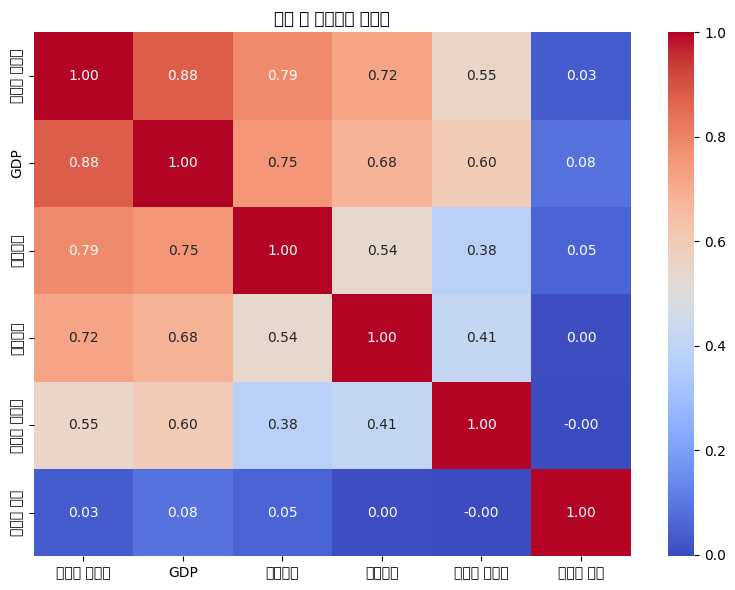

In [ ]:
# 인터넷 보급률과 각 변수들의 관계를 한눈에 파악하기 위해 히트맵 사용
plt.figure(figsize=(8, 6))
corr_df = df_2024[['internet_penetration', 'log_GDP',
                    'literacy_rate', 'urbanization',
                    'mobile_subscriptions', 'Coastline_km']].copy()


corr_df.columns = ['인터넷 보급률', 'GDP', '교육수준', '도시화율', '모바일 보급률', '해안선 길이']

sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('변수 간 상관관계 히트맵')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1014/1739579099.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_2024_valid, x='gap_group', y='gini_index',
/tmp/ipykernel_1014/1739579099.py:36: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/1739579099.py:36: UserWarning: Glyph 45768 (\N{HANGUL SYLLABLE NI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/1739579099.py:36: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/1739579099.py:36: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/1739579099.py:36: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(

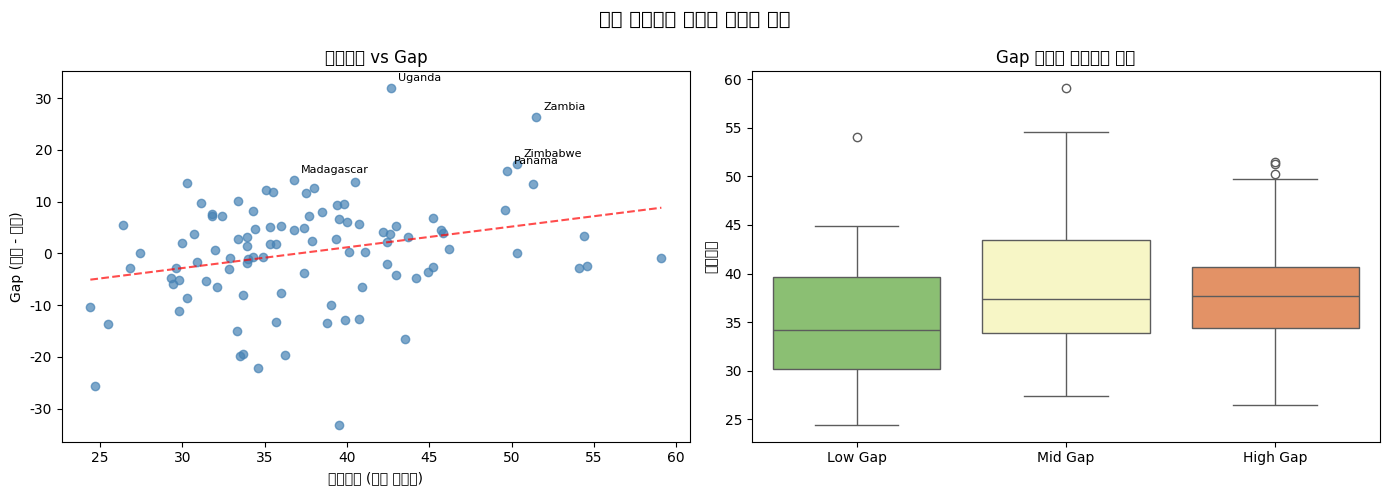

In [ ]:
# 원인 분석 - 소득 불평등 :  지니계수와 Gap의 관계 분석

# Gap 상위 그룹과 하위 그룹 비교
df_2024['gap_group'] = pd.qcut(df_2024['gap'], q=3,
                                labels=['Low Gap', 'Mid Gap', 'High Gap'])

# 지니계수 비교
df_gini = df_2024.dropna(subset=['gini_index'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('소득 불평등과 인터넷 저개발 관계', fontsize=14, fontweight='bold')

# 지니계수 vs Gap
axes[0].scatter(df_gini['gini_index'], df_gini['gap'], alpha=0.7, color='steelblue')
z = np.polyfit(df_gini['gini_index'], df_gini['gap'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_gini['gini_index'].min(), df_gini['gini_index'].max(), 100)
axes[0].plot(x_line, p(x_line), 'r--', alpha=0.7)

# 상위 5개국 표시
top5 = df_gini.nlargest(5, 'gap')
for _, row in top5.iterrows():
    axes[0].annotate(row['Country'], (row['gini_index'], row['gap']),
                     textcoords="offset points", xytext=(5, 5), fontsize=8)

axes[0].set_xlabel('지니계수 (소득 불평등)')
axes[0].set_ylabel('Gap (예측 - 실제)')
axes[0].set_title('지니계수 vs Gap')

# Gap 그룹별 박스플롯
df_2024_valid = df_2024.dropna(subset=['gap_group'])
sns.boxplot(data=df_2024_valid, x='gap_group', y='gini_index',
            palette='RdYlGn_r', ax=axes[1])
axes[1].set_title('Gap 그룹별 지니계수 분포')
axes[1].set_xlabel('')
axes[1].set_ylabel('지니계수')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1014/2486155568.py:32: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/2486155568.py:32: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/2486155568.py:32: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/2486155568.py:32: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/2486155568.py:32: UserWarning: Glyph 45367 (\N{HANGUL SYLLABLE NES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/2486155568.py:32: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/2486155568.py:32: UserWarning: Glyph 44553 (\N{HANGUL SYLLABLE GEUB}) missing from font(s) DejaVu Sans.
  plt.tight_la

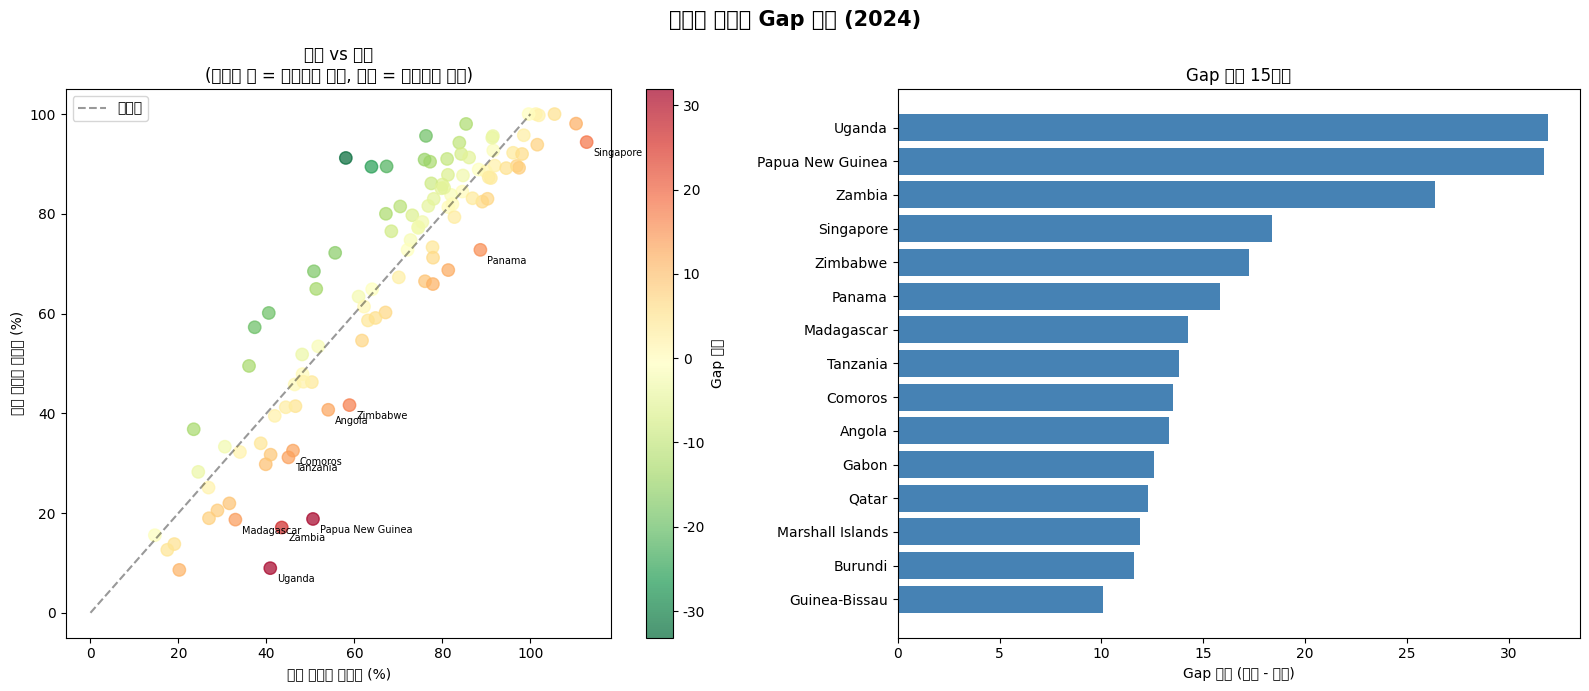

In [ ]:
# Gap 분석 시각화. 예측 vs 실제의 산점도 + Gap 상위 15개국 막대그래프
# 대각선 아래에 있는 나라 = 예측보다 실제 보급률이 낮은 저개발 국가

# Gap 상위 15개국 막대그래프
top15 = df_2024.nlargest(15, 'gap')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('인터넷 보급률 Gap 분석 (2024)', fontsize=15, fontweight='bold')

# 예측 vs 실제 산점도
top_gap = df_2024.nlargest(10, 'gap')
scatter = axes[0].scatter(
    df_2024['predicted'],
    df_2024['internet_penetration'],
    c=df_2024['gap'],
    cmap='RdYlGn_r',
    alpha=0.7, s=80
)
axes[0].plot([0, 100], [0, 100], 'k--', alpha=0.4, label='기준선')
for _, row in top_gap.iterrows():
    axes[0].annotate(row['Country'],
                     (row['predicted'], row['internet_penetration']),
                     textcoords="offset points", xytext=(5, -10), fontsize=7)
plt.colorbar(scatter, ax=axes[0], label='Gap 수치')
axes[0].set_xlabel('예측 인터넷 보급률 (%)')
axes[0].set_ylabel('실제 인터넷 보급률 (%)')
axes[0].set_title('예측 vs 실제\n(기준선 위 = 예측보다 높음, 아래 = 예측보다 낮음)')
axes[0].legend()

# Gap 상위 15개국 막대그래프
axes[1].barh(top15['Country'][::-1], top15['gap'][::-1], color='steelblue')
axes[1].set_title('Gap 상위 15개국')
axes[1].set_xlabel('Gap 수치 (예측 - 실제)')

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

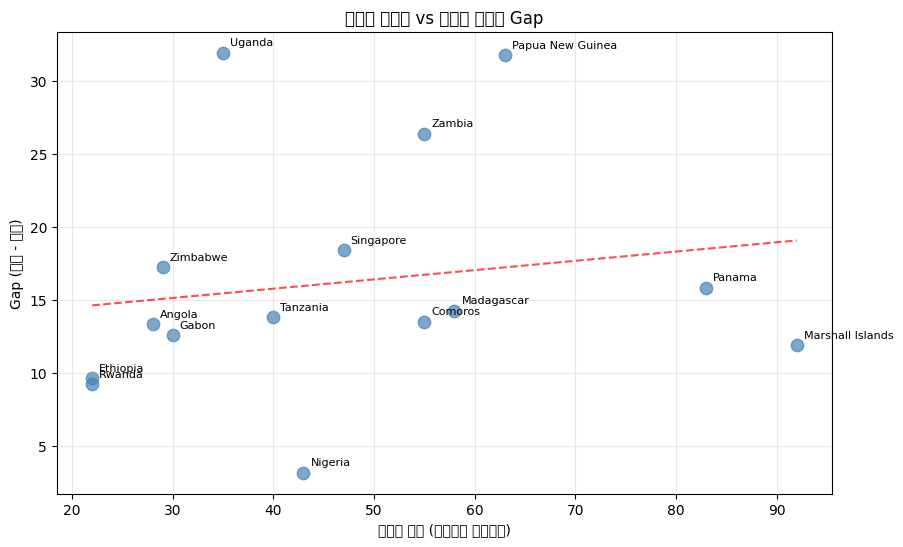

상관계수: 0.166, p-value: 0.555


In [ ]:
# 원인 분석 - 정치적 자유도 : Freedom House 점수와 Gap의 관계 분석
# "억압적인 정부가 인터넷을 통제하여 보급률이 낮은가?"를 검증하기 위해 사용
# Freedom House 점수: 높을수록 자유로운 나라

# 셀 추가 - Freedom House 데이터
freedom_data = {
    'Uganda': 35, 'Zambia': 55, 'Papua New Guinea': 63,
    'Zimbabwe': 29, 'Gabon': 30, 'Angola': 28,
    'Tanzania': 40, 'Panama': 83, 'Singapore': 47,
    'Madagascar': 58, 'Comoros': 55, 'Nigeria': 43,
    'Marshall Islands': 92, 'Ethiopia': 22, 'Rwanda': 22
}

freedom_df = pd.DataFrame(list(freedom_data.items()),
                           columns=['Country', 'freedom_score'])

df_2024 = pd.merge(df_2024, freedom_df, on='Country', how='left')

# Gap vs 자유도 산점도
df_free = df_2024.dropna(subset=['freedom_score'])

plt.figure(figsize=(10, 6))
plt.scatter(df_free['freedom_score'], df_free['gap'], alpha=0.7, s=80, color='steelblue')
z = np.polyfit(df_free['freedom_score'], df_free['gap'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_free['freedom_score'].min(), df_free['freedom_score'].max(), 100)
plt.plot(x_line, p(x_line), 'r--', alpha=0.7)

for _, row in df_free.iterrows():
    plt.annotate(row['Country'], (row['freedom_score'], row['gap']),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)

plt.xlabel('자유도 점수 (높을수록 자유로움)')
plt.ylabel('Gap (예측 - 실제)')
plt.title('정치적 자유도 vs 인터넷 보급률 Gap')
plt.grid(True, alpha=0.3)
plt.show()

# 상관계수
corr, p_val = stats.pearsonr(df_free['freedom_score'], df_free['gap'])
print(f"상관계수: {corr:.3f}, p-value: {p_val:.3f}")

/tmp/ipykernel_1014/942031555.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_valid, x='gap_group', y='electricity_access',
/tmp/ipykernel_1014/942031555.py:59: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/942031555.py:59: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/942031555.py:59: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/942031555.py:59: UserWarning: Glyph 44553 (\N{HANGUL SYLLABLE GEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/942031555.py:59: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) DejaVu Sans.
  plt.tight_layou

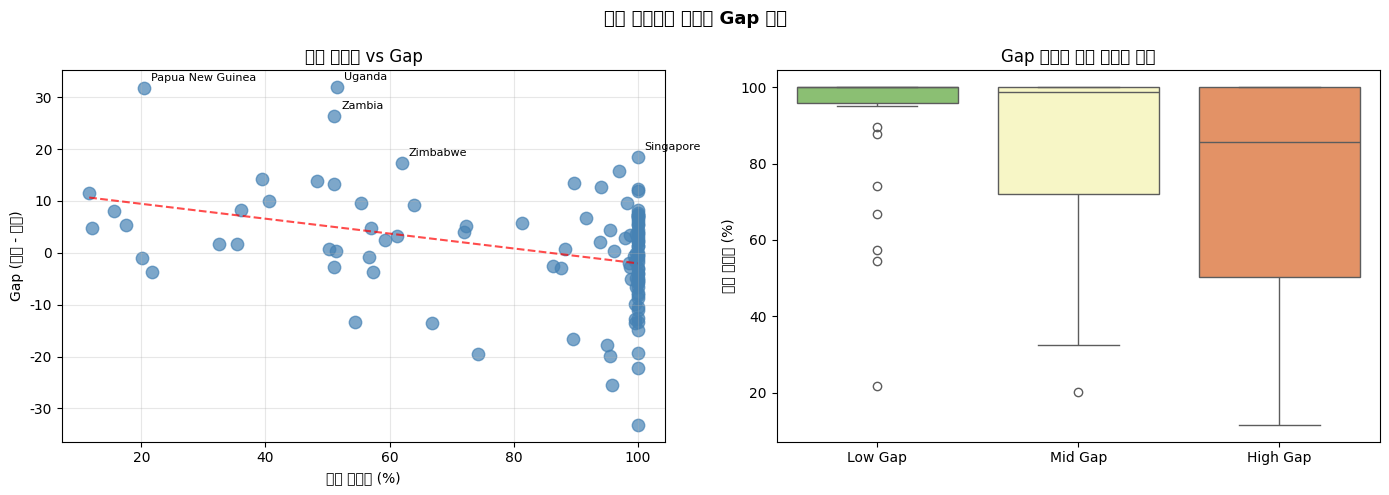

상관계수: -0.349, p-value: 0.000


In [ ]:
# 원인 분석 - 전력 인프라 :  전기 보급률과 Gap의 관계 분석
# "전기가 부족한 나라일수록 인터넷 보급률도 낮은가?"를 검증하기 위해 사용

# 전기 보급률 데이터
df_elec_raw = wb.data.DataFrame(['EG.ELC.ACCS.ZS'], time=range(2010, 2025), labels=True)
df_elec_raw = df_elec_raw.reset_index()

year_cols = [c for c in df_elec_raw.columns if c.startswith('YR')]

df_elec_long = df_elec_raw.melt(
    id_vars=['Country'],
    value_vars=year_cols,
    var_name='Year',
    value_name='electricity_access'
)
df_elec_long['Year'] = df_elec_long['Year'].str.replace('YR', '').astype(int)

# 최근값으로 결측치 채우기
df_elec_long = df_elec_long.sort_values(['Country', 'Year'])
df_elec_long['electricity_access'] = df_elec_long.groupby('Country')['electricity_access'].ffill()

# 2024년만 추출
df_elec_2024 = df_elec_long[df_elec_long['Year'] == 2024][['Country', 'electricity_access']]

# 병합
df_2024 = pd.merge(df_2024, df_elec_2024, on='Country', how='left')

# 전기 보급률 vs Gap 시각화
df_elec_valid = df_2024.dropna(subset=['electricity_access'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('전력 인프라와 인터넷 Gap 관계', fontsize=13, fontweight='bold')

# 산점도
axes[0].scatter(df_elec_valid['electricity_access'], df_elec_valid['gap'],
                alpha=0.7, s=80, color='steelblue')
z = np.polyfit(df_elec_valid['electricity_access'], df_elec_valid['gap'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_elec_valid['electricity_access'].min(),
                      df_elec_valid['electricity_access'].max(), 100)
axes[0].plot(x_line, p(x_line), 'r--', alpha=0.7)

for _, row in df_2024.nlargest(5, 'gap').iterrows():
    if pd.notna(row.get('electricity_access')):
        axes[0].annotate(row['Country'],
                         (row['electricity_access'], row['gap']),
                         textcoords="offset points", xytext=(5, 5), fontsize=8)

axes[0].set_xlabel('전기 보급률 (%)')
axes[0].set_ylabel('Gap (예측 - 실제)')
axes[0].set_title('전기 보급률 vs Gap')
axes[0].grid(True, alpha=0.3)

# 박스플롯
df_valid = df_2024.dropna(subset=['gap_group', 'electricity_access'])
sns.boxplot(data=df_valid, x='gap_group', y='electricity_access',
            palette='RdYlGn_r', ax=axes[1])
axes[1].set_title('Gap 그룹별 전기 보급률 분포')
axes[1].set_xlabel('')
axes[1].set_ylabel('전기 보급률 (%)')

plt.tight_layout()
plt.show()

# 상관계수
corr, p_val = stats.pearsonr(df_elec_valid['electricity_access'], df_elec_valid['gap'])
print(f"상관계수: {corr:.3f}, p-value: {p_val:.3f}")






 전기부족 여부 & Gap 그룹 교차분석 (%)
gap_group   Low Gap  Mid Gap  High Gap
elec_group                            
전기부족           20.4     37.0      42.6
전기충분           45.5     30.9      23.6


/tmp/ipykernel_1014/3862563406.py:26: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/3862563406.py:26: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/3862563406.py:26: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/3862563406.py:26: UserWarning: Glyph 51313 (\N{HANGUL SYLLABLE JOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/3862563406.py:26: UserWarning: Glyph 52649 (\N{HANGUL SYLLABLE CUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/3862563406.py:26: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/3862563406.py:26: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_la

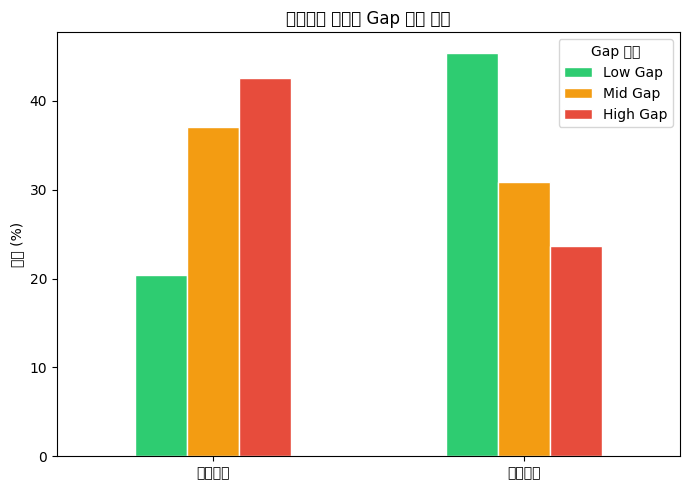

In [ ]:
# 전기부족/충분 두 그룹으로 나눠 High Gap 비율이 실제로 차이나는지 검증하기 위해 사용


# 교차분석 : 전기부족 & Gap 그룹
df_cross = df_2024.dropna(subset=['electricity_access', 'gap_group']).copy()

# 전기 보급률 중앙값 기준으로 부족/충분으로 나눔
df_cross['elec_group'] = (df_cross['electricity_access'] < df_cross['electricity_access'].median()).map({True: '전기부족', False: '전기충분'})

# 교차표
crosstab = pd.crosstab(
    df_cross['elec_group'],
    df_cross['gap_group'],
    normalize='index'
) * 100

print(" 전기부족 여부 & Gap 그룹 교차분석 (%)")
print(crosstab.round(1))

# 시각화
crosstab.plot(kind='bar',
              color=['#2ecc71', '#f39c12', '#e74c3c'],
              edgecolor='white', figsize=(7,5))
plt.title('전기부족 여부별 Gap 그룹 분포')
plt.xlabel('')
plt.ylabel('비율 (%)')
plt.xticks(rotation=0)
plt.legend(title='Gap 그룹')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

인터넷 저개발과 연관된 규칙 Top 10
       antecedents          consequents  support  confidence     lift
      (저도시화, 전기부족)  (인터넷저개발, 저GDP, 저교육) 0.192661    0.525000 2.200962
      (저도시화, 전기부족)       (인터넷저개발, 저GDP) 0.211009    0.575000 2.161207
 (저도시화, 저교육, 전기부족)       (인터넷저개발, 저GDP) 0.192661    0.567568 2.133271
       (전기부족, 저교육)       (인터넷저개발, 저GDP) 0.238532    0.565217 2.124438
      (전기부족, 저GDP)        (인터넷저개발, 저교육) 0.238532    0.565217 2.124438
(저도시화, 저GDP, 전기부족)        (인터넷저개발, 저교육) 0.192661    0.552632 2.077132
      (저도시화, 전기부족)        (인터넷저개발, 저교육) 0.201835    0.550000 2.067241
 (전기부족, 저GDP, 저교육)       (저도시화, 인터넷저개발) 0.192661    0.500000 2.018519
      (전기부족, 저GDP)       (저도시화, 인터넷저개발) 0.211009    0.500000 2.018519
       (저도시화, 저교육) (전기부족, 인터넷저개발, 저GDP) 0.192661    0.512195 1.993902
전체 규칙 수: 36
            antecedents  confidence
200        (저도시화, 전기부족)    0.525000
143        (저도시화, 전기부족)    0.575000
192   (저도시화, 저교육, 전기부족)    0.567568
133         (전기부족, 저교육)    0.565217
132        (전기부

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_1014/1696039987.py:74: UserWarning: Glyph 49888 (\N{HANGUL SYLLABLE SIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1014/1696039987.py:74: UserWarning: Glyph 47280 (\N{HANGUL SYLLABLE ROE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203:

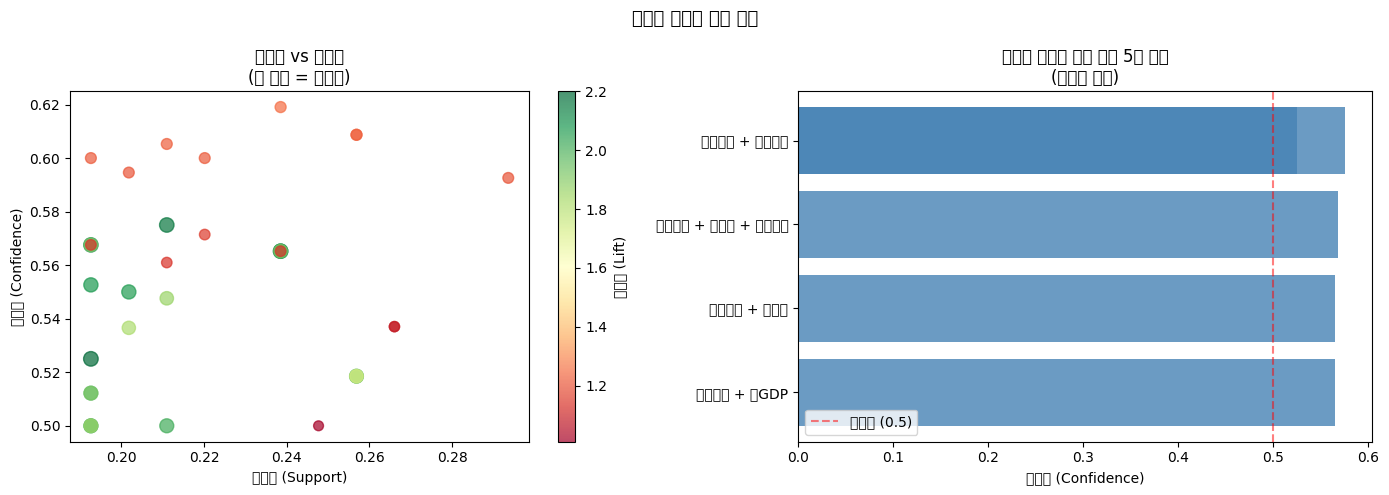

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# 연관분석 : 인터넷 저개발을 예측하는 조건 조합 패턴 탐색
# 어떤 변수들이 함께 나타날 때 인터넷 저개발로 이어지는지 패턴을 찾기 위해 사용


# 변수 이진화 (낮음/높음 기준: 중앙값)
df_assoc = df_2024.copy()
df_assoc['low_electricity'] = df_assoc['electricity_access'] < df_assoc['electricity_access'].median()
df_assoc['low_GDP'] = df_assoc['log_GDP'] < df_assoc['log_GDP'].median()
df_assoc['low_literacy'] = df_assoc['literacy_rate'] < df_assoc['literacy_rate'].median()
df_assoc['low_urbanization'] = df_assoc['urbanization'] < df_assoc['urbanization'].median()
df_assoc['high_gap'] = df_assoc['gap'] > df_assoc['gap'].median()
df_assoc['landlocked'] = df_assoc['is_coastal'] == 0

# 데이터 생성
transactions = []
for _, row in df_assoc.iterrows():
    t = []
    if row['low_electricity']: t.append('전기부족')
    if row['low_GDP']: t.append('저GDP')
    if row['low_literacy']: t.append('저교육')
    if row['low_urbanization']: t.append('저도시화')
    if row['landlocked']: t.append('내륙국')
    if row['high_gap']: t.append('인터넷저개발')
    transactions.append(t)

# 연관분석
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_te = pd.DataFrame(te_array, columns=te.columns_)

frequent_items = apriori(df_te, min_support=0.1, use_colnames=True)
rules = association_rules(frequent_items, metric='confidence', min_threshold=0.5)

# 인터넷저개발이 결과인 규칙만 필터링
rules_internet = rules[rules['consequents'].apply(lambda x: '인터넷저개발' in x)]
rules_internet = rules_internet.sort_values('lift', ascending=False)

print("인터넷 저개발과 연관된 규칙 Top 10")
print("="*70)
print(rules_internet[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
      .head(10).to_string(index=False))

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('인터넷 저개발 예측 규칙', fontsize=13, fontweight='bold')

# 지지도 vs 신뢰도 산점도
scatter = axes[0].scatter(
    rules_internet['support'],
    rules_internet['confidence'],
    c=rules_internet['lift'],
    cmap='RdYlGn',
    s=rules_internet['lift'] * 50,
    alpha=0.7
)
plt.colorbar(scatter, ax=axes[0], label='향상도 (Lift)')
axes[0].set_xlabel('지지도 (Support)')
axes[0].set_ylabel('신뢰도 (Confidence)')
axes[0].set_title('지지도 vs 신뢰도\n(원 크기 = 향상도)')

# Top 5 규칙 막대그래프
top5_rules = rules_internet.head(5).copy()
top5_rules['rule'] = top5_rules['antecedents'].apply(
    lambda x: ' + '.join(list(x))
)
axes[1].barh(top5_rules['rule'][::-1], top5_rules['confidence'][::-1],
             color='steelblue', alpha=0.8)
axes[1].set_xlabel('신뢰도 (Confidence)')
axes[1].set_title('인터넷 저개발 예측 상위 5개 규칙\n(신뢰도 기준)')
axes[1].axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='기준선 (0.5)')
axes[1].legend()

print(f"전체 규칙 수: {len(rules_internet)}")
print(rules_internet[['antecedents', 'confidence']].head(10).to_string())
plt.tight_layout()
plt.show()